# Figure — Neutralization-associated LASV GPC antibody specificity

Publication-style figure assembly for the neutralization section.

**Panels**
- **A** — Significant positive-neutralization GPC peptides mapped to LASV Josiah GPC.
- **B** — Coordinate-aligned LASV/Mammarenavirus neutralization-associated peptide sequences.
- **C** — Neutralization in GP2-region-reactive vs nonreactive survivors, with adjusted effect estimates.
- **D** — GPC positional/structural annotation track for the neutralization-associated region and literature-supported neutralizing-antibody footprints.

This notebook is deliberately figure-focused. It expects outputs from the preceding neutralization analysis (`screen`, `positive_hits`, `mapped_hits`, and survivor-level metadata). Where possible, it can reconstruct them from the standard project files.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

from scipy.stats import mannwhitneyu
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from Bio import SeqIO
from Bio.Align import PairwiseAligner, substitution_matrices

# ---------- paths ----------
LONG_FILE = Path('./output_files/lassa_df_filtered_peps_reactive_3_proteins.csv')
META_FILE = Path('./metadata_files/master_sample_metadata_111226.csv')
REF_FASTA = Path('./ref_seqs/UP000002473_11622_LASV_Josiah_reference.fasta')
GPC_PEP_HITS_POSITION = Path('./output_files/glycoprotein_peptide_hits_112326.csv')

OUTDIR = Path('./output_figures/Fig_neutralization_GPC')
OUTDIR.mkdir(parents=True, exist_ok=True)

# ---------- color-blind-friendly palette ----------
SURVIVOR_COLOR = '#C23B6E'
CONTACT_COLOR = '#2E3050'
BLUE = '#0072B2'
GREEN = '#009E73'
PURPLE = '#CC79A7'
GRAY = '#6E6E6E'
LIGHT_GRAY = '#D9D9D9'

# ---------- publication style ----------
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 8.5,
    'axes.labelsize': 9.5,
    'axes.titlesize': 10,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'axes.linewidth': 0.8,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'svg.fonttype': 'none',
    'pdf.fonttype': 42,
})

# Josiah boundaries used throughout the project
SSP_END = 58
GP1_END = 259


In [2]:
# Inspect the input tables without printing participant-level metadata.
long_df = pd.read_csv(LONG_FILE)
meta_df = pd.read_csv(META_FILE)
gp_hits_w_position = pd.read_csv(GPC_PEP_HITS_POSITION)

In [3]:
long_df_lasv_gp = long_df.loc[(long_df['protein_std'] == 'glycoprotein') & (long_df['cohort'] != 'HBDB')]

In [4]:
long_df_lasv_gp = long_df_lasv_gp.merge(gp_hits_w_position[['sequence', 'ref_start', 'ref_end']], on='sequence', how='left')

In [5]:
long_df_lasv_gp['region'] = pd.NA #adding a new column to the existing dataframe

#assign regions
long_df_lasv_gp.loc[
    (long_df_lasv_gp['ref_start'] >= 58) 
    & (long_df_lasv_gp['ref_end'] <= 116
), 'region'] = 'GP1_58_116'

long_df_lasv_gp.loc[
    (long_df_lasv_gp['ref_start'] >= 300)
    & (long_df_lasv_gp['ref_end'] <= 425)
    , 'region'
] = 'GP2_300_425'

In [6]:
long_df_lasv_gp = long_df_lasv_gp.merge(meta_df[['sample_id', 'Neut_Percent', 'Neut_Result']], left_on = 'individual', right_on='sample_id', how='left', validate='many_to_one')

     region  n_reactive  n_nonreactive  median_neut_reactive  median_neut_nonreactive  rank_biserial      p_value      q_value
 GP1_58_116          60            335             65.507722                50.827182       0.136716 9.059799e-02 9.059799e-02
GP2_300_425         188            207             71.697211                32.007331       0.432367 9.408304e-14 1.881661e-13


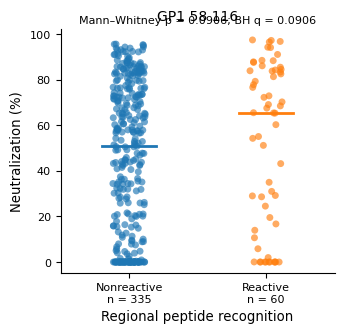

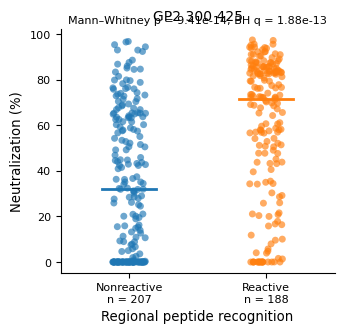

In [7]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

REGION_ORDER = ["GP1_58_116", "GP2_300_425"]

df = long_df_lasv_gp.copy()

# Primary analysis: survivors only.
# Remove this line for a secondary pooled analysis.
df = df.loc[
    df["category"].isin(["Lassa survivor", "Household contact"])
].copy()

df = df.loc[df["region"].isin(REGION_ORDER)].copy()

df["Neut_Percent"] = (
    pd.to_numeric(df["Neut_Percent"], errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
)

# This assumes reactive contains actual Boolean True/False values.
# Do not convert strings using astype(bool): "False" would become True.
if not pd.api.types.is_bool_dtype(df["reactive"]):
    raise TypeError("The reactive column must contain Boolean True/False values.")

if df["reactive"].isna().any():
    raise ValueError(
        "Missing reactive calls are present. Resolve missing measurements "
        "before assigning regional nonreactivity."
    )

# ---------- 1. One binary call per individual per region ----------
regional_scores = (
    df.groupby(["individual", "region"], as_index=False)
    .agg(
        region_reactive=("reactive", "any"),
        n_peptides_measured=("peptide", "nunique"),
    )
)

# ---------- 2. Add sample-level metadata ----------
sample_meta = (
    df[["individual", "category", "Neut_Percent", "Neut_Result"]]
    .drop_duplicates()
)

if sample_meta["individual"].duplicated().any():
    raise ValueError("Conflicting metadata for some individuals.")

#INITIALIZE REGIONAL SCORES
regional_scores = regional_scores.merge(
    sample_meta,
    on="individual",
    how="left",
    validate="many_to_one",
)

# ---------- 3. Compare neutralization between reactive groups ----------
results = []

for region in REGION_ORDER:
    paired = regional_scores.loc[
        regional_scores["region"].eq(region)
    ].dropna(subset=["Neut_Percent"])

    nonreactive = paired.loc[
        ~paired["region_reactive"], "Neut_Percent"
    ]

    reactive = paired.loc[
        paired["region_reactive"], "Neut_Percent"
    ]

    u, p, rank_biserial = np.nan, np.nan, np.nan #rank biserial is an effect size- tells me how strong neutralization values
    #tend to be higher in one group than the other. + 1 would mean every region-reactive individual has higher neutralization than every
    #nonreactive individual. 0 says neither group tends to rank higher overall. -1 would mean every reactive individual has lower neutralization
    #than every nonreactive individual. 

    if len(reactive) > 0 and len(nonreactive) > 0:
        u, p = mannwhitneyu(
            reactive,
            nonreactive,
            alternative="two-sided",
            method="auto",
        )

        # Positive values indicate higher neutralization
        # in region-reactive individuals.
        rank_biserial = (
            2 * u / (len(reactive) * len(nonreactive)) - 1
        )

    results.append({
        "region": region,
        "n_reactive": len(reactive),
        "n_nonreactive": len(nonreactive),
        "median_neut_reactive": reactive.median(),
        "median_neut_nonreactive": nonreactive.median(),
        "rank_biserial": rank_biserial,
        "p_value": p,
    })

association_results = pd.DataFrame(results)
association_results["q_value"] = np.nan

valid = association_results["p_value"].notna()

#correct for multiple testing, because testing recognition of TWO regions

if valid.any():
    association_results.loc[valid, "q_value"] = multipletests(
        association_results.loc[valid, "p_value"],
        method="fdr_bh",
    )[1]

print(association_results.to_string(index=False))

# ---------- 4. Plot neutralization by regional reactivity ----------
rng = np.random.default_rng(42)

for region in REGION_ORDER:
    paired = regional_scores.loc[
        regional_scores["region"].eq(region)
    ].dropna(subset=["Neut_Percent"])

    result = association_results.loc[
        association_results["region"].eq(region)
    ].iloc[0]

    fig, ax = plt.subplots(figsize=(3.5, 3.4))

    for x, status in enumerate([False, True]):
        values = paired.loc[
            paired["region_reactive"].eq(status),
            "Neut_Percent",
        ].to_numpy()

        if len(values) == 0:
            continue

        jitter = rng.uniform(-0.12, 0.12, size=len(values))

        ax.scatter(
            x + jitter,
            values,
            s=25,
            alpha=0.65,
            edgecolors="none",
        )

        # Horizontal line indicates the group median.
        ax.plot(
            [x - 0.20, x + 0.20],
            [np.median(values), np.median(values)],
            linewidth=2,
        )

    ax.set_xticks([0, 1])
    ax.set_xticklabels([
        f"Nonreactive\nn = {int(result['n_nonreactive'])}",
        f"Reactive\nn = {int(result['n_reactive'])}",
    ])

    ax.set_xlim(-0.5, 1.5)
    ax.set_xlabel("Regional peptide recognition")
    ax.set_ylabel("Neutralization (%)")
    ax.set_title(region.replace("_", " "))

    if pd.notna(result["p_value"]):
        ax.text(
            0.5, 1.02,
            f"Mann–Whitney p = {result['p_value']:.3g}; "
            f"BH q = {result['q_value']:.3g}",
            transform=ax.transAxes,
            ha="center",
            fontsize=8,
        )

    fig.tight_layout()
    plt.show()

Individuals excluded because a regional call is missing: 0

Regional recognition overlap among survivors:
GP2 reactive  False  True 
GP1 reactive              
False           177    159
True             30     31

Among GP1-reactive survivors, 31/61 (50.8%) also recognize GP2.

Neutralization by recognition group:
                     n     median        q25        q75
recognition_group                                      
Neither            177  32.456709   0.000000  63.356052
GP1 only            30  26.791583   0.000000  65.535510
GP2 only           158  68.710898  34.729740  83.628346
Both                30  81.991160  55.701773  87.466376

All six pairwise comparisons:
 group_a  group_b  n_a  n_b  median_a  median_b  rank_biserial_B_vs_A      p_value      q_value
 Neither GP1 only  177   30 32.456709 26.791583              0.009605 9.335924e-01 9.335924e-01
 Neither GP2 only  177  158 32.456709 68.710898              0.408425 9.358535e-11 5.615121e-10
 Neither     Both  177   30 

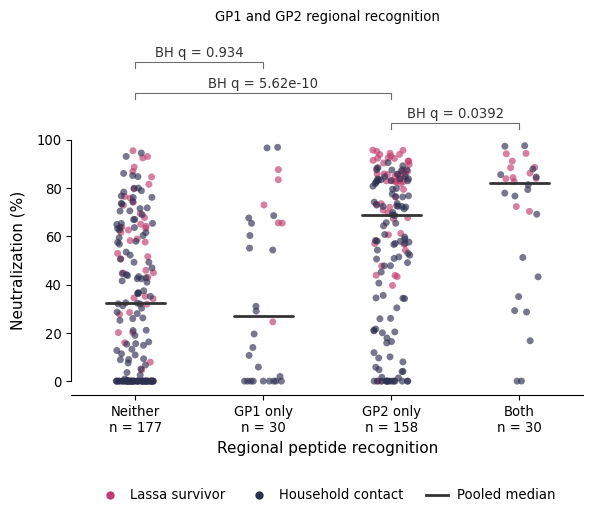

In [8]:
# ---------- 1. One row per individual, with GP1 and GP2 calls ----------
region_calls = regional_scores.pivot(
    index="individual",
    columns="region",
    values="region_reactive",
).reindex(columns=["GP1_58_116", "GP2_300_425"])

# Missing region measurements must not be treated as nonreactive.
complete = region_calls.notna().all(axis=1)

print(
    "Individuals excluded because a regional call is missing:",
    (~complete).sum()
)

region_calls = region_calls.loc[complete].copy()

gp1 = region_calls["GP1_58_116"].astype(bool)
gp2 = region_calls["GP2_300_425"].astype(bool)

region_calls["recognition_group"] = np.select(
    [
        ~gp1 & ~gp2,
         gp1 & ~gp2,
        ~gp1 &  gp2,
         gp1 &  gp2,
    ],
    [
        "Neither",
        "GP1 only",
        "GP2 only",
        "Both",
    ],
    default="Unassigned",
)

# ---------- 2. Add neutralization and category ----------
sample_meta = (
    regional_scores[
        ["individual", "category", "Neut_Percent"]
    ]
    .drop_duplicates()
)

if sample_meta["individual"].duplicated().any():
    raise ValueError("Conflicting metadata for some individuals.")

four_groups = (
    region_calls.reset_index()
    .merge(
        sample_meta,
        on="individual",
        how="left",
        validate="one_to_one",
    )
)

# Keep the same survivor-only population as the previous analysis.
four_groups = four_groups.loc[
    four_groups["category"].isin(['Lassa survivor', 'Household contact'])
].copy()

four_groups["Neut_Percent"] = pd.to_numeric(
    four_groups["Neut_Percent"], errors="coerce"
).replace([np.inf, -np.inf], np.nan)

# ---------- 3. Inspect GP1/GP2 overlap ----------
print("\nRegional recognition overlap among survivors:")
print(pd.crosstab(
    four_groups["GP1_58_116"],
    four_groups["GP2_300_425"],
    rownames=["GP1 reactive"],
    colnames=["GP2 reactive"],
))

gp1_positive = four_groups["GP1_58_116"].eq(True)
n_gp1 = gp1_positive.sum()

if n_gp1 > 0:
    n_both = (
        gp1_positive
        & four_groups["GP2_300_425"].eq(True)
    ).sum()

    print(
        f"\nAmong GP1-reactive survivors, "
        f"{n_both}/{n_gp1} ({100 * n_both / n_gp1:.1f}%) "
        "also recognize GP2."
    )

# ---------- 4. Summarize neutralization in the four groups ----------
GROUP_ORDER = ["Neither", "GP1 only", "GP2 only", "Both"]

plot_df = four_groups.dropna(subset=["Neut_Percent"]).copy()

summary = (
    plot_df.groupby("recognition_group")["Neut_Percent"]
    .agg(
        n="count",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
    )
    .reindex(GROUP_ORDER)
)

summary["n"] = summary["n"].fillna(0).astype(int)

print("\nNeutralization by recognition group:")
print(summary.to_string())

from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# ---------- 5. Pairwise statistics ----------
GROUP_ORDER = ["Neither", "GP1 only", "GP2 only", "Both"]

# plot_df already contains individuals with measured neutralization.
pairwise_results = []

for group_a, group_b in combinations(GROUP_ORDER, 2):
    values_a = plot_df.loc[
        plot_df["recognition_group"].eq(group_a),
        "Neut_Percent",
    ].to_numpy()

    values_b = plot_df.loc[
        plot_df["recognition_group"].eq(group_b),
        "Neut_Percent",
    ].to_numpy()

    u, p, effect = np.nan, np.nan, np.nan

    if len(values_a) > 0 and len(values_b) > 0:
        # Put group B first so a positive effect means
        # higher neutralization in B than A.
        u, p = mannwhitneyu(
            values_b,
            values_a,
            alternative="two-sided",
            method="auto",
        )

        effect = 2 * u / (len(values_a) * len(values_b)) - 1

    pairwise_results.append({
        "group_a": group_a,
        "group_b": group_b,
        "n_a": len(values_a),
        "n_b": len(values_b),
        "median_a": np.median(values_a) if len(values_a) else np.nan,
        "median_b": np.median(values_b) if len(values_b) else np.nan,
        "rank_biserial_B_vs_A": effect,
        "p_value": p,
    })

pairwise_results = pd.DataFrame(pairwise_results)
pairwise_results["q_value"] = np.nan

valid = pairwise_results["p_value"].notna()

if valid.any():
    pairwise_results.loc[valid, "q_value"] = multipletests(
        pairwise_results.loc[valid, "p_value"],
        method="fdr_bh",
    )[1]

print("\nAll six pairwise comparisons:")
print(pairwise_results.to_string(index=False))


## ---------- 6. Plot using cohort colors ----------
from matplotlib.lines import Line2D

COHORT_ORDER = ["Lassa survivor", "Household contact"]

COHORT_COLORS = {
    "Lassa survivor": "#C23B6E",
    "Household contact": '#2E3050',
}



MEDIAN_COLOR = "#333333"
BRACKET_COLOR = "#6E6E6E"

rng = np.random.default_rng(42)

fig, ax = plt.subplots(figsize=(6, 5.2))

for x, group in enumerate(GROUP_ORDER):
    group_df = plot_df.loc[
        plot_df["recognition_group"].eq(group)
    ]

    # Color individual points by cohort.
    # Both cohorts remain centered on the same recognition-group position.
    for cohort in COHORT_ORDER:
        values = group_df.loc[
            group_df["category"].eq(cohort),
            "Neut_Percent",
        ].to_numpy()

        if len(values) == 0:
            continue

        jitter = rng.uniform(-0.15, 0.15, size=len(values))

        ax.scatter(
            x + jitter,
            values,
            s=25,
            color=COHORT_COLORS[cohort],
            alpha=0.65,
            edgecolors="none",
            zorder=2,
        )

    # Pooled median, matching the pooled statistical comparisons.
    pooled_values = group_df["Neut_Percent"].dropna().to_numpy()

    if len(pooled_values):
        ax.plot(
            [x - 0.23, x + 0.23],
            [np.median(pooled_values)] * 2,
            color=MEDIAN_COLOR,
            linewidth=2,
            solid_capstyle="round",
            zorder=3,
        )

ax.set_xticks(range(len(GROUP_ORDER)))
ax.set_xticklabels([
    f"{group}\nn = {summary.loc[group, 'n']}"
    for group in GROUP_ORDER
])

ax.set_xlim(-0.5, 3.5)
ax.set_xlabel("Regional peptide recognition")
ax.set_ylabel("Neutralization (%)")
ax.set_title(
    "GP1 and GP2 regional recognition",
    pad=12,
)

# ---------- Statistical annotations ----------
# All six comparisons were tested and BH-adjusted above.
# Only these three are displayed.
DISPLAY_COMPARISONS = [
    ("GP2 only", "Both"),
    ("Neither", "GP2 only"),
    ("Neither", "GP1 only"),
]

y_min = plot_df["Neut_Percent"].min()
y_max = plot_df["Neut_Percent"].max()

if pd.isna(y_min) or pd.isna(y_max):
    raise ValueError("No neutralization measurements available.")

y_span = max(y_max - y_min, 20)
bracket_height = 0.025 * y_span
step = 0.13 * y_span

for level, (group_a, group_b) in enumerate(DISPLAY_COMPARISONS):
    result = pairwise_results.loc[
        pairwise_results["group_a"].eq(group_a)
        & pairwise_results["group_b"].eq(group_b)
    ].iloc[0]

    q = result["q_value"]

    if pd.isna(q):
        continue

    x1 = GROUP_ORDER.index(group_a)
    x2 = GROUP_ORDER.index(group_b)
    y = y_max + 0.07 * y_span + level * step

    ax.plot(
        [x1, x1, x2, x2],
        [y, y + bracket_height, y + bracket_height, y],
        color=BRACKET_COLOR,
        linewidth=0.8,
    )

    ax.text(
        (x1 + x2) / 2,
        y + bracket_height + 0.01 * y_span,
        f"BH q = {q:.3g}",
        ha="center",
        va="bottom",
        fontsize=8,
        color=MEDIAN_COLOR,
    )

ax.set_ylim(
    y_min - 0.06 * y_span,
    y_max + 0.07 * y_span + len(DISPLAY_COMPARISONS) * step,
)

# ---------- Legend ----------
legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="none",
        markerfacecolor=COHORT_COLORS[cohort],
        markeredgecolor="none",
        markersize=6,
        label=cohort,
    )
    for cohort in COHORT_ORDER
]

legend_handles.append(
    Line2D(
        [0], [0],
        color=MEDIAN_COLOR,
        linewidth=2,
        label="Pooled median",
    )
)

ax.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.23),
    ncol=3,
    frameon=False,
    fontsize=8,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

from matplotlib.text import Text

# All text at 9.5 pt
for text in fig.findobj(match=Text):
    text.set_fontsize(9.5)

# Larger x- and y-axis labels
ax.xaxis.label.set_fontsize(11)
ax.yaxis.label.set_fontsize(11)

# Keep the existing ylim so there is room for statistical annotations.
# Only label the biological measurement range.
ax.set_yticks(np.arange(0, 101, 20))

# End the visible y-axis line at 100%.
ax.spines["left"].set_bounds(0, 100)

# Center the y-axis label beside the 0–100% data range,
# rather than beside the data plus annotation space.
y_bottom, y_top = ax.get_ylim()
label_center = (50 - y_bottom) / (y_top - y_bottom)
ax.yaxis.set_label_coords(-0.09, label_center)

fig.tight_layout()
plt.show()

 #Optional export:
fig.savefig(
    OUTDIR / "GP1_GP2_recognition_by_cohort.svg", format='svg',
   bbox_inches="tight",
)
# fig.savefig(
#     OUTDIR / "GP1_GP2_recognition_by_cohort.png",
#     dpi=300,
#     bbox_inches="tight",
# )

plt.show()

In [9]:
print(
    pd.crosstab(
        four_groups["recognition_group"],
        four_groups["category"],
    ).reindex(["Neither", "GP1 only", "GP2 only", "Both"])
)

category           Household contact  Lassa survivor
recognition_group                                   
Neither                          131              46
GP1 only                          24               6
GP2 only                         103              56
Both                              19              12


In [10]:
print(
    four_groups.groupby(
        ["category", "recognition_group"]
    )["Neut_Percent"]
    .agg(n="count", median="median")
)

                                       n     median
category          recognition_group                
Household contact Both                18  72.914272
                  GP1 only            24  12.298137
                  GP2 only           102  56.824441
                  Neither            131  25.180148
Lassa survivor    Both                12  85.243432
                  GP1 only             6  69.269981
                  GP2 only            56  83.141869
                  Neither             46  55.258105


## 1. Load/reconstruct the neutralization screen

The figure uses only **positive-direction neutralization associations**:
`FDR_screen < 0.05` and `delta_median_neut > 0`.


## starting with Survivors

In [11]:
df = pd.read_csv(LONG_FILE)
meta = pd.read_csv(META_FILE)

meta['collection_date'] = pd.to_datetime(meta['collection_date'], errors='coerce')

baseline = (
    meta.sort_values(['participant_id','collection_date'])
        .groupby('participant_id', as_index=False)
        .first()
)

survivors = baseline.loc[baseline['Category'].isin(['S'])].copy()

keep_meta = [
    'sample_id','participant_id','Neut_Percent','GP_Calc_Conc',
    'age_years','sex','years_since_discharge'
]

survivor_meta = survivors[keep_meta].copy()
survivor_meta['sample_id'] = survivor_meta['sample_id'].astype(str)

# LASV GPC
lasv_gpc = df.loc[
    df['species'].astype(str).str.contains('lassa', case=False, na=False)
    & df['protein_std'].eq('glycoprotein')
].copy()

lasv_gpc['individual'] = lasv_gpc['individual'].astype(str)

lasv_neut = lasv_gpc.merge(
    survivor_meta,
    left_on='individual',
    right_on='sample_id',
    how='inner'
)

lasv_neut = lasv_neut.loc[lasv_neut['Neut_Percent'].notna()].copy()

rows = []
for peptide, g in lasv_neut.groupby('peptide'):
    g = g.drop_duplicates('individual')
    pos = g.loc[g['reactive'].astype(bool), 'Neut_Percent'].dropna()
    neg = g.loc[~g['reactive'].astype(bool), 'Neut_Percent'].dropna()
    if len(pos) < 3 or len(neg) < 3:
        continue
    _, p = mannwhitneyu(pos, neg, alternative='two-sided')
    r0 = g.iloc[0]
    rows.append({
        'peptide': peptide,
        'sequence': r0['sequence'],
        'species': r0['species'],
        'accession': r0.get('accession', np.nan),
        'n_reactive': len(pos),
        'n_nonreactive': len(neg),
        'median_neut_reactive': pos.median(),
        'median_neut_nonreactive': neg.median(),
        'delta_median_neut': pos.median() - neg.median(),
        'p_screen': p
    })

screen = pd.DataFrame(rows)
screen['FDR_screen'] = multipletests(screen['p_screen'], method='fdr_bh')[1]

positive_hits = (
    screen.loc[
        (screen['FDR_screen'] < 0.05)
        & (screen['delta_median_neut'] > 0)
    ]
    .sort_values('FDR_screen')
    .copy()
)

print('LASV GPC peptides tested:', len(screen))
print('Positive neutralization-associated hits:', len(positive_hits))
display(positive_hits)


LASV GPC peptides tested: 16
Positive neutralization-associated hits: 11


/tmp/ipykernel_130217/1025480696.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  meta['collection_date'] = pd.to_datetime(meta['collection_date'], errors='coerce')


,peptide,sequence,species,accession,n_reactive,n_nonreactive,median_neut_reactive,median_neut_nonreactive,delta_median_neut,p_screen,FDR_screen
5,AZI96412.1|precursor|Mammarenavirus_lassaense|...,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPKCWLVSNGS,Mammarenavirus lassaense,AZI96412.1,30,88,86.760952,65.507722,21.253230,1.157934e-07,0.000002
3,AZI96059.1|precursor|Mammarenavirus_lassaense|...,NDQLIMKNHLRDIMGIPYCNYSKYWYLNNTVTGKSSLPKCWLVSNG,Mammarenavirus lassaense,AZI96059.1,32,86,86.349969,66.403041,19.946928,1.811954e-06,0.000010
6,AZI96476.1|precursor|Mammarenavirus_lassaense|...,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTITGKTSLPRCWLVSNGS,Mammarenavirus lassaense,AZI96476.1,35,83,86.166650,67.722491,18.444158,1.239494e-06,0.000010
9,AZI96488.1|precursor|Mammarenavirus_lassaense|...,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPRCWLVSNGT,Mammarenavirus lassaense,AZI96488.1,35,83,85.841573,67.242783,18.598790,4.309758e-06,0.000017
0,AHC95553.1|precursor|Mammarenavirus_lassaense|...,TSLPKCWLVSNGSYLNETHFSDDIEQQADNMITEMLQKEYMDRQGK,Mammarenavirus lassaense,AHC95553.1,24,94,87.618931,68.569823,19.049108,6.488869e-06,0.000021
2,ANH09740.1|precursor|Mammarenavirus_lassaense|...,CNEKHDEEFCDMWRLFDFNKQAIQRLKAEAQMNIQLINKAVNALIN,Mammarenavirus lassaense,ANH09740.1,47,71,84.984398,64.203796,20.780602,2.038991e-05,0.000047
15,XBA96065.1|precursor|Mammarenavirus_lassaense|...,KCNEKHDEEFCDMLRLFDFNKQAIQRLKAEAQMSIQLINKAVNALI,Mammarenavirus lassaense,XBA96065.1,50,68,84.484379,63.994275,20.490105,2.003584e-05,0.000047
4,AZI96059.1|precursor|Mammarenavirus_lassaense|...,YWYLNNTVTGKSSLPKCWLVSNGSYLNETHFSEDIEQQADNMITEM,Mammarenavirus lassaense,AZI96059.1,18,100,87.908520,69.534578,18.373942,3.426302e-05,0.000069
10,AZI96488.1|precursor|Mammarenavirus_lassaense|...,WYLNHTVTGKTSLPRCWLVSNGTYLNETHFSDDIEQQADNMITELL,Mammarenavirus lassaense,AZI96488.1,23,95,86.988617,69.676952,17.311664,6.758745e-05,0.000120
7,AZI96476.1|precursor|Mammarenavirus_lassaense|...,WYLNHTITGKTSLPRCWLVSNGSYLNETQFSDDIEQQADNMITELL,Mammarenavirus lassaense,AZI96476.1,22,96,87.618931,69.993715,17.625216,1.955781e-04,0.000313


In [21]:
screen.peptide.to_list()

['AHC95553.1|precursor|Mammarenavirus_lassaense|?|Mastomys_natalensis|Mali|Jun-2009|S|Soromba-R|tile_19',
 'AHC95553.1|precursor|Mammarenavirus_lassaense|?|Mastomys_natalensis|Mali|Jun-2009|S|Soromba-R|tile_5',
 'ANH09740.1|precursor|Mammarenavirus_lassaense|?|Hylomyscus_pamfi|Nigeria|15-Mar-2012|?|KAK-428|tile_14',
 'AZI96059.1|precursor|Mammarenavirus_lassaense|LASV/H.sapiens-tc/NGA/2012/IRR_006|Homo_sapiens|Nigeria:_Rivers|21-Feb-2012|S|?|tile_16',
 'AZI96059.1|precursor|Mammarenavirus_lassaense|LASV/H.sapiens-tc/NGA/2012/IRR_006|Homo_sapiens|Nigeria:_Rivers|21-Feb-2012|S|?|tile_17',
 'AZI96412.1|precursor|Mammarenavirus_lassaense|LASV/H.sapiens-wt/NGA/2018/IRR_064|Homo_sapiens|Nigeria:_EBONYI|03-Feb-2018|S|?|tile_16',
 'AZI96476.1|precursor|Mammarenavirus_lassaense|LASV/H.sapiens-wt/NGA/2018/IRR_119|Homo_sapiens|Nigeria:_EDO|25-Feb-2018|S|?|tile_16',
 'AZI96476.1|precursor|Mammarenavirus_lassaense|LASV/H.sapiens-wt/NGA/2018/IRR_119|Homo_sapiens|Nigeria:_EDO|25-Feb-2018|S|?|tile_17'

## 2. Josiah GPC reference and full-peptide mapping

In [13]:
records = list(SeqIO.parse(REF_FASTA, 'fasta'))

for i, rec in enumerate(records):
    print(i, rec.id, len(rec.seq), rec.description)

gpc_candidates = [
    r for r in records
    if ('glycoprotein' in r.description.lower()
        or 'gpc' in r.description.lower()
        or 'precursor' in r.description.lower())
]

if len(gpc_candidates) != 1:
    raise ValueError(
        'Could not uniquely identify GPC. Inspect records above and set gpc_ref manually.'
    )

gpc_ref = str(gpc_candidates[0].seq)

aligner = PairwiseAligner()
aligner.mode = 'local'
aligner.substitution_matrix = substitution_matrices.load('BLOSUM62')
aligner.open_gap_score = -10
aligner.extend_gap_score = -0.5


0 sp|O09705|L_LASSJ 2218 sp|O09705|L_LASSJ RNA-directed RNA polymerase L OS=Lassa virus (strain Mouse/Sierra Leone/Josiah/1976) OX=11622 GN=L PE=3 SV=1
1 sp|O73557|Z_LASSJ 99 sp|O73557|Z_LASSJ RING finger protein Z OS=Lassa virus (strain Mouse/Sierra Leone/Josiah/1976) OX=11622 GN=Z PE=1 SV=4
2 sp|P08669|GLYC_LASSJ 491 sp|P08669|GLYC_LASSJ Pre-glycoprotein polyprotein GP complex OS=Lassa virus (strain Mouse/Sierra Leone/Josiah/1976) OX=11622 GN=GPC PE=1 SV=1
3 sp|P13699|NCAP_LASSJ 569 sp|P13699|NCAP_LASSJ Nucleoprotein OS=Lassa virus (strain Mouse/Sierra Leone/Josiah/1976) OX=11622 GN=N PE=1 SV=1


In [14]:
def align_full_peptide_to_reference(peptide, reference, aligner):
    peptide = str(peptide).upper()
    reference = str(reference).upper()

    alns = aligner.align(reference, peptide)
    if len(alns) == 0:
        return None

    aln = alns[0]
    ref_blocks, pep_blocks = aln.aligned
    if len(ref_blocks) == 0:
        return None

    pep_to_ref = {}
    for (r0,r1),(p0,p1) in zip(ref_blocks, pep_blocks):
        block_len = min(r1-r0, p1-p0)
        for off in range(block_len):
            pep_to_ref[p0+off] = r0+off+1

    if not pep_to_ref:
        return None

    first_p = min(pep_to_ref)
    first_r = pep_to_ref[first_p]
    full_start = first_r - first_p
    full_end = full_start + len(peptide) - 1

    return {
        'full_start': int(full_start),
        'full_end': int(full_end),
        'pep_to_ref': pep_to_ref,
        'score': aln.score
    }

mapped = []
for _, row in positive_hits.iterrows():
    res = align_full_peptide_to_reference(row['sequence'], gpc_ref, aligner)
    if res is None:
        continue
    mapped.append({**row.to_dict(), **res})

mapped_hits = (
    pd.DataFrame(mapped)
      .sort_values(['full_start','full_end'])
      .reset_index(drop=True)
)

display(
    mapped_hits[
        ['peptide','full_start','full_end','delta_median_neut','FDR_screen','sequence']
    ]
)


,peptide,full_start,full_end,delta_median_neut,FDR_screen,sequence
0,XBA96065.1|precursor|Mammarenavirus_lassaense|...,300,345,20.490105,0.000047,KCNEKHDEEFCDMLRLFDFNKQAIQRLKAEAQMSIQLINKAVNALI
1,ANH09740.1|precursor|Mammarenavirus_lassaense|...,301,346,20.780602,0.000047,CNEKHDEEFCDMWRLFDFNKQAIQRLKAEAQMNIQLINKAVNALIN
2,AZI96059.1|precursor|Mammarenavirus_lassaense|...,346,391,19.946928,0.000010,NDQLIMKNHLRDIMGIPYCNYSKYWYLNNTVTGKSSLPKCWLVSNG
3,AZI96412.1|precursor|Mammarenavirus_lassaense|...,347,392,21.253230,0.000002,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPKCWLVSNGS
4,AZI96476.1|precursor|Mammarenavirus_lassaense|...,347,392,18.444158,0.000010,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTITGKTSLPRCWLVSNGS
5,AZI96488.1|precursor|Mammarenavirus_lassaense|...,347,392,18.598790,0.000017,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPRCWLVSNGT
6,AZI96059.1|precursor|Mammarenavirus_lassaense|...,369,414,18.373942,0.000069,YWYLNNTVTGKSSLPKCWLVSNGSYLNETHFSEDIEQQADNMITEM
7,AZI96488.1|precursor|Mammarenavirus_lassaense|...,370,415,17.311664,0.000120,WYLNHTVTGKTSLPRCWLVSNGTYLNETHFSDDIEQQADNMITELL
8,AZI96476.1|precursor|Mammarenavirus_lassaense|...,370,415,17.625216,0.000313,WYLNHTITGKTSLPRCWLVSNGSYLNETQFSDDIEQQADNMITELL
9,UCR17178.1|precursor|Mammarenavirus_lassaense|...,370,415,15.018658,0.004337,WYLNHTTTGRTSLPRCWLVSNGSYLNETHFSDDIEQQADNMITEML


In [15]:
peps_w_neut_surv = mapped_hits['peptide'].to_list()

df = pd.DataFrame(peps_w_neut_surv)

df.to_csv('peptides_sign_w_neut_in_surv.csv')

# Panel A — significant GPC peptides mapped to Josiah

Full library-tile lengths are displayed, rather than only the locally aligned subsection.


In [16]:
def add_gpc_labels(ax, ref_length, detailed=True):
    transform = ax.get_xaxis_transform()

    # Broad subunit track
    for label, start, end in [
        ("SSP", 1, 58),
        ("GP1", 59, 259),
        ("GP2", 260, ref_length),
    ]:
        ax.plot(
            [start, end],
            [1.24, 1.24],
            transform=transform,
            color="0.55",
            lw=3,
            solid_capstyle="butt",
            clip_on=False,
        )

        ax.text(
            (start + end) / 2,
            1.27,
            label,
            transform=transform,
            ha="center",
            va="bottom",
            fontsize=10,
            clip_on=False,
        )

    if not detailed:
        return

    # Focus on features relevant to the antibody results.
    features = [
        ("FP",     260, 275),
        ("FL",     276, 295),
        ("HR1",    308, 358),
        ("T-loop", 364, 385),
        ("HR2",    395, 411),
    ]

    for label, start, end in features:
        ax.plot(
            [start, end],
            [1.06, 1.06],
            transform=transform,
            color="0.55",
            lw=2,
            solid_capstyle="butt",
            clip_on=False,
        )

        # Stagger FP and FL because their intervals are adjacent.
        label_y = 1.08

        ax.text(
            (start + end) / 2,
            label_y,
            label,
            transform=transform,
            ha="center",
            va="bottom",
            fontsize=9,
            clip_on=False,
        )

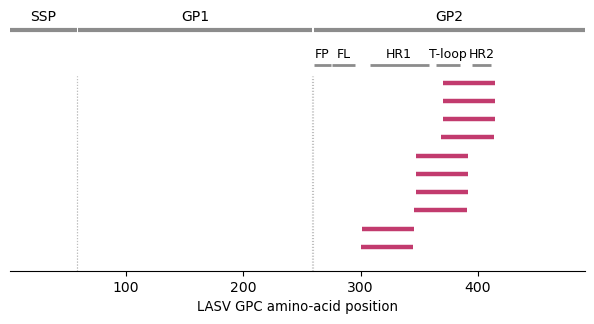

In [17]:
fig, ax = plt.subplots(figsize=(6, 3.5))


# domains
for x in [SSP_END, GP1_END]:
    ax.axvline(x, color='0.75', lw=0.8, ls=':')

for i, row in mapped_hits.iterrows():
    y = 0.0 + i * 0.13
    ax.plot(
        [row['full_start'], row['full_end']],
        [y, y],
        color=SURVIVOR_COLOR,
        lw=3.2,
        solid_capstyle='butt'
    )

ax.set_xlim(1, len(gpc_ref))
ax.set_ylim(-0.17, 0.28 + len(mapped_hits)*0.085)
ax.tick_params(axis='x', labelsize=10)
ax.set_xlabel('LASV GPC amino-acid position')
ax.set_yticks([])
ax.spines['left'].set_visible(False)


GPC_BOUNDARIES = [58, 259]

for boundary in GPC_BOUNDARIES:
            ax.axvline(
                boundary + 0.5,
                color="0.75",
                lw=0.8,
                ls=":",
                zorder=0,
            )

reference = len(gpc_ref)

add_gpc_labels(
            ax,
            ref_length=reference,
        )

fig.tight_layout()
fig.savefig(OUTDIR/'Panel_A_GPC_neutralization_hits.svg', bbox_inches='tight')
fig.savefig(OUTDIR/'Panel_A_GPC_neutralization_hits.pdf', bbox_inches='tight')
plt.show()


# Panel C — region recognition vs neutralization

Region-positive = survivor recognizes **at least one** significant LASV GPC peptide in the mapped neutralization-associated region.

The panel reports:
- raw participant-level neutralization distributions;
- secondary GP-ELISA-adjusted effect.

The GP-ELISA adjustment asks whether region recognition carries information beyond overall GP-binding antibody magnitude.


In [18]:
region_peptides = mapped_hits['peptide'].tolist()

g = lasv_neut.loc[lasv_neut['peptide'].isin(region_peptides)].copy()

region_data = (
    g.groupby('individual', as_index=False)
     .agg(
         region_reactive=('reactive','max'),
         Neut_Percent=('Neut_Percent','first'),
         GP_Calc_Conc=('GP_Calc_Conc','first')
     )
)

region_data['region_reactive'] = region_data['region_reactive'].astype(int)

pos = region_data.loc[region_data['region_reactive']==1, 'Neut_Percent'].dropna()
neg = region_data.loc[region_data['region_reactive']==0, 'Neut_Percent'].dropna()

_, p_raw = mannwhitneyu(pos, neg, alternative='two-sided')


print('Region positive:', len(pos), 'Region negative:', len(neg))
print('Median +:', pos.median(), 'Median -:', neg.median())
print('Raw MW p:', p_raw)


Region positive: 66 Region negative: 52
Median +: 83.922969285 Median -: 60.256990314999996
Raw MW p: 4.428131284382316e-07


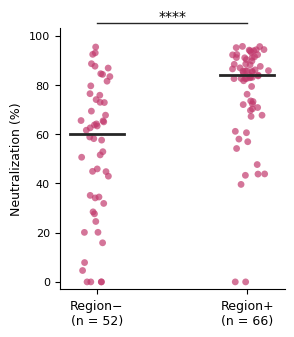

In [19]:
# Deterministic jitter for display only
rng = np.random.default_rng(11)

fig, ax = plt.subplots(figsize=(3, 4))

for x, vals in [(0, neg), (1, pos)]:
    jitter = rng.normal(0, 0.055, len(vals))
    ax.scatter(
        np.full(len(vals), x) + jitter,
        vals,
        s=24,
        alpha=0.70,
        color=SURVIVOR_COLOR,
        edgecolor='none'
    )

    med = np.median(vals)
    ax.plot([x-0.18, x+0.18], [med, med], color='0.15', lw=2)

ax.set_xticks([0,1])
ax.set_xticks([0, 1])
ax.set_xticklabels([
    f'Region−\n(n = {len(neg)})',
    f'Region+\n(n = {len(pos)})',
], fontsize=9)
ax.set_ylabel('Neutralization (%)', fontsize=9)
ax.set_ylim(-3, 103)

if p_raw < 0.0001:
    stars = '****'
elif p_raw < 0.001: 
    starts = '***'
elif p_raw < 0.01:
    stars = '**'
elif p_raw < 0.05:
    stars = '*'
else: 
    stars = 'ns'

# significance bracket
y = 105
h = 0.025

ax.plot(
    [0, 0, 1, 1],
    [y, y+h, y+h, y],
    color='0.15',
    lw=1,
    clip_on=False
)

ax.text(
    0.5,
    y + h + 0.01,
    stars,
    ha='center',
    va='bottom',
    fontsize=10, 
    clip_on=False
)


fig.tight_layout(rect=[0,0,1,0.86])
fig.savefig(OUTDIR/'Panel_C_region_neutralization_survivors.svg', bbox_inches='tight')
fig.savefig(OUTDIR/'Panel_C_region_neutralization_survivors.pdf', bbox_inches='tight')
plt.show()


## Figure-legend draft

**Neutralization-associated LASV glycoprotein antibody specificity.**  
**(A)** LASV GPC peptides whose recognition was significantly associated with higher serum neutralization after Benjamini–Hochberg correction, mapped to the LASV Josiah GPC reference. Full peptide-tile lengths are shown.  
**(B)** Coordinate-aligned sequences of neutralization-associated GPC peptides relative to Josiah; dots indicate identity to the reference and letters indicate amino-acid substitutions. Δ denotes the difference in median neutralization between peptide-reactive and peptide-nonreactive survivors.  
**(C)** Serum neutralization among survivors with or without recognition of the neutralization-associated GPC region. Horizontal bars denote medians. Adjusted effects were estimated by multivariable linear regression including age, sex, and years since discharge; a secondary model additionally adjusted for log-transformed GP ELISA concentration.  
**(D)** Location of the PhIP-Seq neutralization-associated region relative to literature-supported neutralizing-antibody structural, escape, or mutagenesis footprints. Structural annotations should be added only after source verification.
